<h1>CCA</h1>

```mermaid
flowchart TD
A[Missing Value] --> B[Remove Them]
A --> C[Impute Them]
C --> D{Univariate: SimpleImputer}
C --> E{Multivariate: KNNImputer, IterativeImputer}
D --> F[Numerical]
D --> G[Categorical]
F --> H[Mean / Median]
F --> I[Random Value]
F --> J[End of Distribution]
G --> K[Mode]
G --> L[Random Value]
G --> M[Missing Category]
```



`SimpleImputer` has four strategies:

| Strategy | Fills missing values with | Works on |
|---|---|---|
| `"mean"` (default) | Column mean | Numeric only |
| `"median"` | Column median | Numeric only |
| `"most_frequent"` | Most common value (mode) | Numeric and categorical |
| `"constant"` | The value you set in `fill_value` | Numeric and categorical |


<h2>1. Remove Them</h2>

- the column must have null values less then 5%
- if null value is 95% then remove that column
- after removing null row then % of data we lost
- the distribution of col remain same before and after removing null
- for column the ratio must be mentained

In [1]:
import numpy as np
import pandas as pd
import  matplotlib.pyplot as plt
import seaborn as sns
from IPython.terminal.shortcuts.filters import pass_through


In [2]:
try:

    df = pd.read_csv(r'/home/mukul/Main/Basic_DataScience-4ML/assets/data/data_science_job.csv',
                     header=0,
                     index_col=0,
                     engine='python',
                     on_bad_lines='skip'

                     )

except Exception as e:
    print(e)

In [3]:
df

,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
enrollee_id,,,,,,,,,,,,
8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
7386,city_173,0.878,Male,No relevent experience,no_enrollment,Graduate,Humanities,14.0,NaN,NaN,42.0,1.0
31398,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,14.0,NaN,NaN,52.0,1.0
24576,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,50-99,Pvt Ltd,44.0,0.0


In [4]:
df.isnull().mean()*100

city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

extract the columns having 5% null Only For Num

In [5]:
def seave(df,threshold):
    new_df=pd.DataFrame()
    for col in df:
        if df[col].isnull().mean()*100 < threshold and df[col].isnull().mean()*100 !=0:
            new_df[col] = df[col]


    return new_df


In [6]:
new_df=seave(df,5)

In [7]:
new_df

,city_development_index,enrolled_university,education_level,experience,training_hours
enrollee_id,,,,,
8949,0.920,no_enrollment,Graduate,20.0,36.0
29725,0.776,no_enrollment,Graduate,15.0,47.0
11561,0.624,Full time course,Graduate,5.0,83.0
33241,0.789,NaN,Graduate,0.0,52.0
666,0.767,no_enrollment,Masters,20.0,8.0
...,...,...,...,...,...
7386,0.878,no_enrollment,Graduate,14.0,42.0
31398,0.920,no_enrollment,Graduate,14.0,52.0
24576,0.920,no_enrollment,Graduate,20.0,44.0


Drop rows having 5% null or drop col if 95% null

In [8]:
new_df.dropna(inplace=True)

In [9]:
new_df.isnull().mean()*100

city_development_index    0.0
enrolled_university       0.0
education_level           0.0
experience                0.0
training_hours            0.0
dtype: float64

In [10]:
def seave1(df,threshold):
    df1=pd.DataFrame()
    for col in df:
        if df[col].isnull().mean()*100 < threshold and df[col].isnull().mean()*100 !=0:
            df1[col] = df[col]


    return df1

In [11]:
df1=seave1(df,5)

how % data is removed

In [12]:
len(df)

19158

In [13]:
len(new_df)/len(df)*100

89.68577095730244

In [14]:
df1

,city_development_index,enrolled_university,education_level,experience,training_hours
enrollee_id,,,,,
8949,0.920,no_enrollment,Graduate,20.0,36.0
29725,0.776,no_enrollment,Graduate,15.0,47.0
11561,0.624,Full time course,Graduate,5.0,83.0
33241,0.789,NaN,Graduate,0.0,52.0
666,0.767,no_enrollment,Masters,20.0,8.0
...,...,...,...,...,...
7386,0.878,no_enrollment,Graduate,14.0,42.0
31398,0.920,no_enrollment,Graduate,14.0,52.0
24576,0.920,no_enrollment,Graduate,20.0,44.0


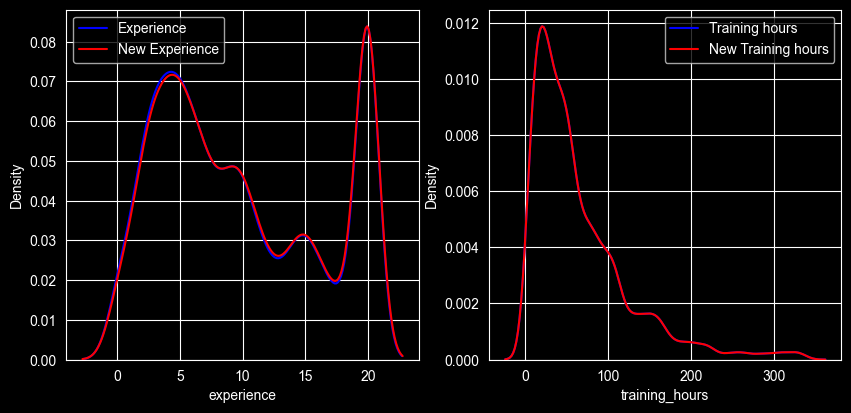

In [15]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
sns.kdeplot(df1['experience'],color='blue')
sns.kdeplot(new_df['experience'],color='red')
plt.legend(['Experience','New Experience'])

plt.subplot(2,2,2)
sns.kdeplot(new_df['training_hours'],color='blue')
sns.kdeplot(new_df['training_hours'],color='red')
plt.legend(['Training hours','New Training hours'])


Extracting data from cate col having null

In [16]:
df2 = df['enrolled_university']

In [17]:
df2.isnull().mean()*100

2.0148240943731075

In [18]:
df2.dropna(inplace=True)

In [19]:
df2.isnull().sum()

0

In [20]:
df['enrolled_university'].isnull().sum()

386

we removed null now compare the ratio with the old dataset and it must be same

In [21]:
temp = pd.concat([
    df['enrolled_university'].value_counts()/len(df['enrolled_university']),
    df2.value_counts()/len(df2),

],axis='columns')
temp.columns = ['old_enrolled_university','new_enrolled_university']

In [22]:
temp

,old_enrolled_university,new_enrolled_university
enrolled_university,,
no_enrollment,0.721213,0.736043
Full time course,0.196106,0.200139
Part time course,0.062533,0.063818


In [23]:
temp = pd.concat([
    df2.reset_index(drop=True),
    df['enrolled_university'].reset_index(drop=True),
],axis=1)
temp.columns = ['old_enrolled_university','new_enrolled_university']

In [24]:
temp['new_enrolled_university'].isnull().sum()

386

<h1>2. Impute them</h1>

there are few ways we can use to impute num column in univarient

- mean/median
  - only do when data missing at random
  - imputing data less then 5%
  - it causes outliers and decrease co-varience/relation

In [25]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import  make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

In [26]:
try:
    df = pd.read_csv(r'/home/mukul/Main/Basic_DataScience-4ML/assets/data/titanic.csv',
                     index_col=0,
                     engine='python',
                     on_bad_lines='skip',
                     header=0,


                     )

except Exception as e:
    print(e)

In [27]:
x = df.drop(columns=['Survived'])
y = df['Survived']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=0)

In [28]:
mean_imputer = make_pipeline(
    SimpleImputer(strategy='mean'),
)

median_imputer = make_pipeline(
    SimpleImputer(strategy='median'),
)

In [29]:
cr = ColumnTransformer(transformers=[
    ('mean_imputer',mean_imputer,['Age']),
    ('median_imputer',median_imputer,['Age']),
    ('mean_imputer1',mean_imputer,['Fare']),
    ('median_imputer1',median_imputer,['Fare'])
],remainder='drop')

In [30]:
x_train_transformed = cr.fit_transform(x_train)

In [31]:
x_train_transformed

array([[29.74518389, 29.        , 15.2458    , 15.2458    ],
       [31.        , 31.        , 10.5       , 10.5       ],
       [31.        , 31.        , 37.0042    , 37.0042    ],
       ...,
       [29.74518389, 29.        ,  7.7333    ,  7.7333    ],
       [36.        , 36.        , 17.4       , 17.4       ],
       [60.        , 60.        , 39.        , 39.        ]])

In [32]:
df3 = pd.DataFrame(x_train_transformed,columns=['Age_mean','Age_median','Fare_mean','Fare_median'])

In [33]:
result = pd.concat([
    x_train
    ,df3
],axis=1)

In [34]:
result['Age_mean'].isnull().sum()

147

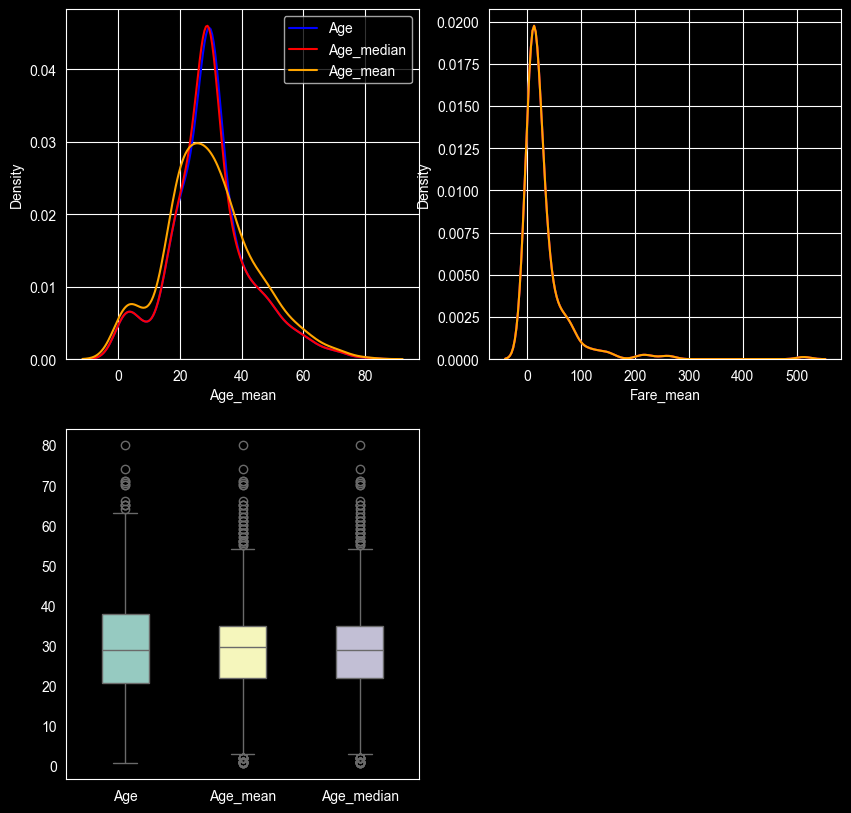

In [35]:
plt.figure(figsize=(10,10))

plt.subplot(2,2,1)

sns.kdeplot(data=result,x='Age_mean',color='blue')
sns.kdeplot(data=result,x='Age_median',color='red')
sns.kdeplot(data=result,x='Age',color='orange')
plt.legend(['Age','Age_median','Age_mean'])
plt.subplot(2,2,2)
sns.kdeplot(data=result,x='Fare_mean',color='blue')
sns.kdeplot(data=result,x='Fare_median',color='red')
sns.kdeplot(data=result,x='Fare',color='orange')

plt.subplot(2,2,3)
sns.boxplot(
    data=result[['Age', 'Age_mean', 'Age_median']],
    width=0.4
)

plt.grid(axis='y')
plt.show()



* **Arbitrary Imputer**

  * Used to replace `NaN/Null` values with an **arbitrary value** chosen by us.

  * Common arbitrary values:

    * Numerical → `-999`, `999`, `0`
    * Categorical → `"Missing"`, `"Unknown"`

  * Useful when data is **Not Missing At Random (NMAR)**, where the missingness itself may contain information.

  * The arbitrary value should be **outside the normal range** of the variable so that the model can distinguish imputed values from actual values.

  * It can **change the covariance and relationships** between variables.

  * Mostly useful for **categorical variables**, where `"Missing"` or `"Unknown"` can represent a separate category.

  * For numerical variables, arbitrary imputation can introduce **outliers**, so the chosen value should be considered carefully.

  * Unlike mean/median imputation, it does **not preserve the original distribution** of the variable.



In [36]:
imputer = SimpleImputer(strategy="constant", fill_value=-999)
print(imputer.fit_transform(X))

NameError: name 'X' is not defined

* **End of Distribution Imputer**

  * Used to replace missing values with values at the **end of the distribution**.

  * If Data Set is **Normally Distributed** then use:

    * **Upper End:** `Mean + 3σ`
    * **Lower End:** `Mean - 3σ`

  * If Data Set is **Skewed** then use:

    * **Upper End:** `Q3 + 1.5 × IQR`
    * **Lower End:** `Q1 - 1.5 × IQR`
    * where `IQR = Q3 - Q1`

  * For **right-skewed data**, the upper end is generally more useful.

  * For **left-skewed data**, the lower end is generally more useful.

  * It helps preserve the **distribution shape** better than simply replacing missing values with the mean or median.

  * It can be useful when missing values themselves may carry information and we want to place them at an extreme but valid point in the distribution.

  * **Important:** The imputed value should be calculated using the **training data only** to avoid data leakage.


In [ ]:
end_value = np.nanmean(X) + 3 * np.nanstd(X)

imputer = SimpleImputer(strategy="constant", fill_value=end_value)
print(imputer.fit_transform(X))

- Random Imputer
    - Memory Heavy Train data then find random number
    - Prevent varience Best for linear Model
        - extract random value from data set itself but the random value = sample value

In [ ]:
missing = df["age"].isna()
df.loc[missing, "age"] = df["age"].dropna().sample(missing.sum(), replace=True).values

Auto Select Imputer
Grid-Search CV

In [ ]:
from  sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import  OneHotEncoder, OrdinalEncoder, StandardScaler, KBinsDiscretizer
from  sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from  sklearn.compose import ColumnTransformer


from sklearn.linear_model import LogisticRegression
import  numpy as np
import pandas as pd

In [ ]:
try:

    df = pd.read_csv(r'/home/mukul/Main/Basic_DataScience-4ML/assets/data/titanic.csv',
                     usecols=['Survived','Pclass','Sex','Age','Fare','Embarked'],
                     header=0,
                     # index_col=0,
                     engine='python',
                     on_bad_lines='skip'

                     )

except Exception as e:
    print(e)

In [ ]:
df

In [ ]:
df.info()

In [ ]:
x = df.drop(columns=['Survived'],axis=1)
y = df['Survived']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=0)

In [ ]:
num_pipeline = make_pipeline(
    SimpleImputer(strategy='mean'),
)

cat_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(),
)

In [ ]:
cr = ColumnTransformer(transformers=[
    ('num_pipeline',num_pipeline,['Age']),
    ('cat_pipeline',cat_pipeline,['Embarked','Sex']),
],remainder='passthrough')

In [ ]:
model = make_pipeline(
    cr,
    LogisticRegression(max_iter=1000)
)

In [ ]:
model.fit(x_train,y_train)

In [ ]:
num_pipeline.get_params()

## Nested Parameters (`__` Notation) — Theory

**Definition:**
A parameter access convention in scikit-learn that allows setting or retrieving hyperparameters of an estimator nested inside another estimator, using a single flattened string with double underscores (`__`) as path separators.

**Underlying mechanism:**
Implemented via the `get_params()` and `set_params()` methods defined in sklearn's `BaseEstimator` class. Every estimator inherits these methods, which recursively expose nested objects' parameters as flattened key-value pairs.

**Applicable to (meta-estimators):**
Any estimator that internally holds other estimators:
- `Pipeline`
- `ColumnTransformer`
- `VotingClassifier` / `VotingRegressor`
- `StackingClassifier` / `StackingRegressor`
- `GridSearchCV` / `RandomizedSearchCV` (they wrap an estimator too)
- `MultiOutputClassifier`, `OneVsRestClassifier`, etc.

**Path construction rule:**
```
<step_name_level_1>__<step_name_level_2>__...__<parameter_name>
```
- Each intermediate segment corresponds to a **step's assigned name**.
- The final segment corresponds to a **constructor argument** of the innermost estimator/transformer.

**Naming source (two cases):**
| Construction method | Step naming behavior |
|---|---|
| `Pipeline([('name', obj), ...])` / `ColumnTransformer([('name', obj, cols), ...])` | Name is explicitly user-defined |
| `make_pipeline(obj1, obj2)` / `make_column_transformer(...)` | Name is auto-generated as the lowercase class name of the object |

**Purpose / rationale:**
Enables a single, flat hyperparameter search space to span an arbitrarily deep nested model architecture, so tools like `GridSearchCV` and `RandomizedSearchCV` can optimize parameters at every level (preprocessing, transformation, estimator) simultaneously within one search.

**Formal terminology (as used in sklearn documentation and API design):**
- "Nested parameters"
- "Parameter path" (the string itself)
- Governed by the **`get_params()` / `set_params()` API contract**, which all sklearn-compatible estimators must implement to support this behavior — this is part of the scikit-learn estimator API convention.

**Constraint:**
Every key used in a nested parameter dictionary must correspond to a valid, existing path in that specific object's structure; an invalid path raises `ValueError` at fit time, not at dictionary-construction time.

In [ ]:
parameter_grid = {
    'columntransformer__num_pipeline__simpleimputer__strategy': ['mean','median','most_frequent'],
    'logisticregression__C': [0.1, 1, 10],
}

In [ ]:
gscv = GridSearchCV(model,param_grid=parameter_grid,scoring='neg_mean_squared_error',n_jobs=-1,cv=5)

In [ ]:
gscv.fit(x_train,y_train)

In [ ]:
print(gscv.best_params_)
print(gscv.best_score_)

best_model = gscv.best_estimator_
print(best_model.score(x_test, y_test))

- The Best way to impute and find above is sklearn can be used but a better approach
    - but the Problem is this method only best for single col
    - if there are more col so this algo apply same impute to all col if 1st col use that impute not per col imputer finder

In [ ]:
from feature_engine.imputation import (
    MeanMedianImputer, ArbitraryNumberImputer, EndTailImputer, RandomSampleImputer
)
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

num_pipeline = make_pipeline(MeanMedianImputer(imputation_method='mean'))  # placeholder, gets swapped
cat_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder())

cr = ColumnTransformer(transformers=[
    ('num_pipeline', num_pipeline, ['Age']),
    ('cat_pipeline', cat_pipeline, ['Embarked', 'Sex']),
], remainder='passthrough')

model = make_pipeline(cr, LogisticRegression(max_iter=1000))

parameter_grid = {
    'columntransformer__num_pipeline__meanmedianimputer': [
        MeanMedianImputer(imputation_method='mean'),
        MeanMedianImputer(imputation_method='median'),
        ArbitraryNumberImputer(arbitrary_number=-999),
        EndTailImputer(imputation_method='gaussian', tail='right'),
        RandomSampleImputer(random_state=42),
    ],
    'logisticregression__C': [0.1, 1, 10],
}

gscv = GridSearchCV(model, param_grid=parameter_grid, scoring='accuracy', cv=5, n_jobs=-1)
gscv.fit(x_train, y_train)

In [ ]:
results_df = pd.DataFrame(gscv.cv_results_)

In [ ]:
results_df

- Multivarient Imputer
    - KNN Imputer
    - Iterative Imputer

# KNN Imputer: Quick Notes

## Idea
Fill a missing value using the values of the **k most similar rows** (nearest neighbors). Similarity is measured by distance computed on the features that are not missing.

## Steps
1. Pick a row with a missing value in feature *j*.
2. Compute its distance to every other row that has feature *j* observed.
3. Select the **k nearest** rows.
4. Impute feature *j* from those neighbors' values (mean or weighted mean).
5. Repeat for every missing cell.

## Imputation Formulas

**Uniform (simple average):**

x̂ⱼ = (1/k) · Σᵢ₌₁ᵏ vᵢ

**Distance-weighted:**

x̂ⱼ = ( Σᵢ wᵢ · vᵢ ) / ( Σᵢ wᵢ ), where wᵢ = 1 / dᵢ

- vᵢ = value of feature *j* in the i-th neighbor
- dᵢ = distance to the i-th neighbor (closer neighbors get more weight)
- For categorical features, use the **mode** of the neighbors instead of the mean.

## Standard Euclidean Distance (no missing values)

d(x, y) = √( Σᵢ₌₁ⁿ (xᵢ − yᵢ)² )

## NaN-Euclidean Distance (when data is missing)

Only use coordinates that are **present in both** rows, then scale up to compensate for the skipped ones:

d(x, y) = √( (n / m) · Σ over present coords (xᵢ − yᵢ)² )

- n = total number of features
- m = number of features present in **both** x and y
- (n / m) = weight factor that compensates for the missing coordinates
- If no coordinates overlap (m = 0), the distance is NaN.

**Example:** n = 4, x = [1, NaN, 3, 5], y = [2, 4, NaN, 9]
Common coords: 1st and 4th, so m = 2.

d = √( (4/2) · [(1−2)² + (5−9)²] ) = √(2 · 17) = √34 ≈ 5.83

## Key Points
- **Scale the features first** (standardize or min-max), since distance is scale-sensitive.
- **k**: small k is noisy (high variance); large k over-smooths (high bias). Tune it with cross-validation.
- **Weights**: uniform treats all neighbors equally; distance weighting favors closer ones.
- Works best when the data has real local structure (similar rows have similar values).

## Pros
- Uses relationships between features, so it is better than mean/median imputation
- Non-parametric, with no distribution assumption
- Handles multiple missing columns

## Cons
- Slow on large datasets (computes distances to all rows), roughly O(n²·d)
- Sensitive to outliers and irrelevant features
- Needs scaling, and the choice of k matters
- Struggles in high dimensions (curse of dimensionality)